In [2]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt

df = sns.load_dataset('tips')

print(df.head())

   total_bill   tip     sex smoker  day    time  size
0       16.99  1.01  Female     No  Sun  Dinner     2
1       10.34  1.66    Male     No  Sun  Dinner     3
2       21.01  3.50    Male     No  Sun  Dinner     3
3       23.68  3.31    Male     No  Sun  Dinner     2
4       24.59  3.61  Female     No  Sun  Dinner     4


In [3]:
print("Dataset Shape:", df.shape)

Dataset Shape: (244, 7)


In [4]:
print(df.columns)

Index(['total_bill', 'tip', 'sex', 'smoker', 'day', 'time', 'size'], dtype='str')


In [5]:
print(df.dtypes)

total_bill     float64
tip            float64
sex           category
smoker        category
day           category
time          category
size             int64
dtype: object


In [6]:
print(df.isnull().sum())

total_bill    0
tip           0
sex           0
smoker        0
day           0
time          0
size          0
dtype: int64


In [7]:
num_cols = ['total_bill', 'tip', 'size']
cat_cols = ['sex', 'smoker', 'day', 'time']

for col in num_cols:
    df[col] = df[col].fillna(df[col].median())

for col in cat_cols:
    df[col] = df[col].fillna(df[col].mode()[0])

print(df.isnull().sum())

total_bill    0
tip           0
sex           0
smoker        0
day           0
time          0
size          0
dtype: int64


In [8]:
from sklearn.preprocessing import LabelEncoder

le = LabelEncoder()

df['sex'] = le.fit_transform(df['sex'])
df['smoker'] = le.fit_transform(df['smoker'])
df['day'] = le.fit_transform(df['day'])
df['time'] = le.fit_transform(df['time'])

print(df.head())

   total_bill   tip  sex  smoker  day  time  size
0       16.99  1.01    0       0    2     0     2
1       10.34  1.66    1       0    2     0     3
2       21.01  3.50    1       0    2     0     3
3       23.68  3.31    1       0    2     0     2
4       24.59  3.61    0       0    2     0     4


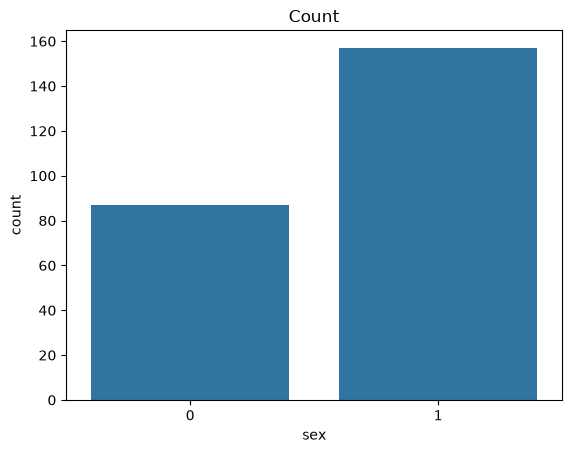

In [10]:
sns.countplot(x='sex', data=df)

plt.title("Count")
plt.show()

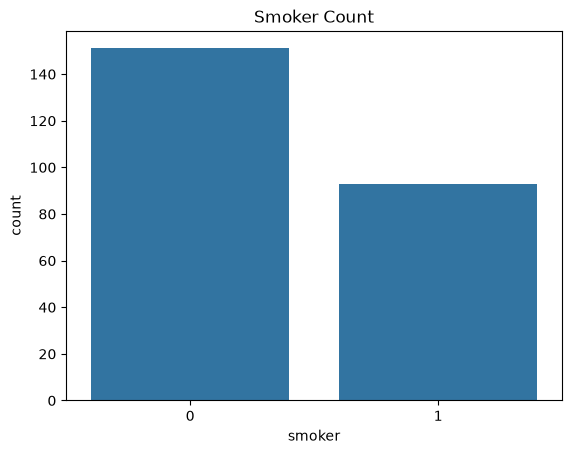

In [11]:
sns.countplot(x='smoker', data=df)

plt.title("Smoker Count")
plt.show()

In [12]:
print("Sex Frequency:")
print(df['sex'].value_counts())

print("Smoker Frequency:")
print(df['smoker'].value_counts())

print("Day Frequency:")
print(df['day'].value_counts())

print("Time Frequency:")
print(df['time'].value_counts())

Sex Frequency:
sex
1    157
0     87
Name: count, dtype: int64
Smoker Frequency:
smoker
0    151
1     93
Name: count, dtype: int64
Day Frequency:
day
1    87
2    76
3    62
0    19
Name: count, dtype: int64
Time Frequency:
time
0    176
1     68
Name: count, dtype: int64


In [13]:
print("Sex Percentage:")
print(df['sex'].value_counts(normalize=True) * 100)

print("Smoker Percentage:")
print(df['smoker'].value_counts(normalize=True) * 100)

print("Day Percentage:")
print(df['day'].value_counts(normalize=True) * 100)

print("Time Percentage:")
print(df['time'].value_counts(normalize=True) * 100)

Sex Percentage:
sex
1    64.344262
0    35.655738
Name: proportion, dtype: float64
Smoker Percentage:
smoker
0    61.885246
1    38.114754
Name: proportion, dtype: float64
Day Percentage:
day
1    35.655738
2    31.147541
3    25.409836
0     7.786885
Name: proportion, dtype: float64
Time Percentage:
time
0    72.131148
1    27.868852
Name: proportion, dtype: float64


In [14]:
print("Most Common Sex:", df['sex'].mode()[0])

print("Most Common Smoker:", df['smoker'].mode()[0])

print("Most Common Day:", df['day'].mode()[0])

print("Most Common Time:", df['time'].mode()[0])

Most Common Sex: 1
Most Common Smoker: 0
Most Common Day: 1
Most Common Time: 0


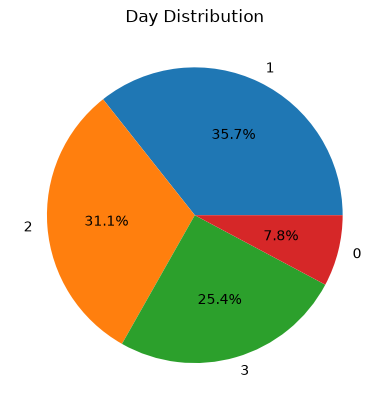

In [15]:
df['day'].value_counts().plot(
    kind='pie',
    autopct='%1.1f%%'
)

plt.title("Day Distribution")
plt.ylabel("")
plt.show()

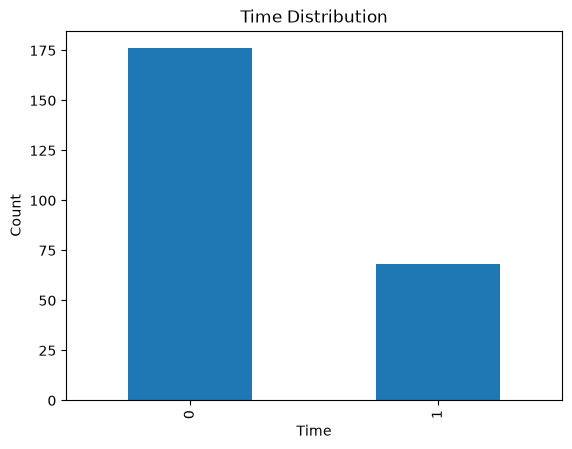

In [16]:
df['time'].value_counts().plot(kind='bar')

plt.title("Time Distribution")
plt.xlabel("Time")
plt.ylabel("Count")
plt.show()

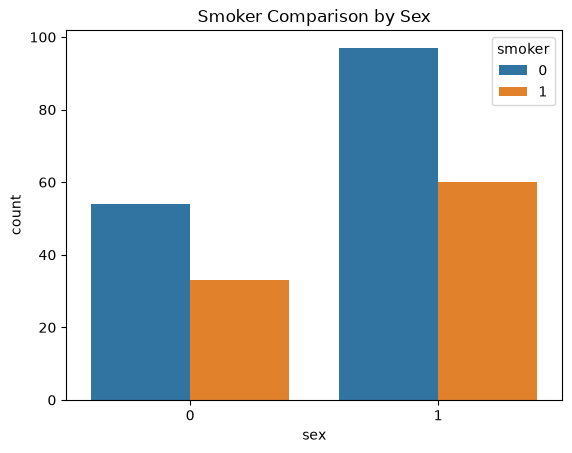

In [17]:
sns.countplot(x='sex', hue='smoker', data=df)

plt.title("Smoker Comparison by Sex")
plt.show()